# Задание 2.3
## Корни из комплексных чисел

### Условие:
Вычислите (над полем $\mathbb C$) и изобразите на комплексной плоскости:
$$
a)\ \sqrt[8]{1};\quad b)\ \sqrt[4]{-\frac{18}{1+i\sqrt3}};\quad c)\ \sqrt[3]{\frac{1-5i}{1+i}-5\,\frac{1+2i}{2-i}+11};\quad d)\ \sqrt[9]{1-i}.
$$

### Теория:
Корень $n$-й степени из $w=\rho e^{i\theta}\ne0$ принимает $n$ значений:
$$
z_k=\sqrt[n]{\rho}\,e^{i(\theta+2\pi k)/n},\quad k=0,\dots,n-1.
$$

### Подкоренные выражения:
- **a)** $w=1$, $\rho=1$, $\theta=0$; корни: $z_k=e^{i\pi k/4}$.
- **b)** $1+i\sqrt3=2e^{i\pi/3}$, поэтому $-\dfrac{18}{1+i\sqrt3}=-9e^{-i\pi/3}=9e^{i(\pi-\pi/3)}=9e^{2\pi i/3}$. Корни: $\sqrt[4]9=\sqrt3$ и аргументы $\dfrac{\pi}{6}+\dfrac{\pi k}{2}$.
- **c)** $\dfrac{1-5i}{1+i}=\dfrac{(1-5i)(1-i)}{2}=\dfrac{-4-6i}{2}=-2-3i$, а $\dfrac{1+2i}{2-i}=\dfrac{(1+2i)(2+i)}{5}=\dfrac{5i}{5}=i$. Тогда $w=-2-3i-5i+11=9-8i$, $|w|=\sqrt{145}$.
- **d)** $1-i=\sqrt2e^{-i\pi/4}$; корни: $2^{1/18}$ и аргументы $\dfrac{-\pi/4+2\pi k}{9}$.

In [1]:
import numpy as np

def root_n(w, n):
    '''все n значений корня n-й степени из w'''
    k = np.arange(n)
    return abs(w)**(1/n)*np.exp(1j*(np.angle(w) + 2*np.pi*k)/n)

w = {
    'a': (1 + 0j, 8),
    'b': (-18/(1 + 1j*np.sqrt(3)), 4),
    'c': ((1 - 5j)/(1 + 1j) - 5*(1 + 2j)/(2 - 1j) + 11, 3),
    'd': (1 - 1j, 9),
}
roots = {}
for name, (val, n) in w.items():
    roots[name] = root_n(val, n)
    print(f'{name}) w = {val.real:.6f}{val.imag:+.6f}i,  |w| = {abs(val):.6f},  Arg w = {np.angle(val):.6f},  n = {n}')
    for kk, zz in enumerate(roots[name]):
        print(f'      z_{kk} = {zz.real: .6f} {zz.imag:+.6f}i')

a) w = 1.000000+0.000000i,  |w| = 1.000000,  Arg w = 0.000000,  n = 8
      z_0 =  1.000000 +0.000000i
      z_1 =  0.707107 +0.707107i
      z_2 =  0.000000 +1.000000i
      z_3 = -0.707107 +0.707107i
      z_4 = -1.000000 +0.000000i
      z_5 = -0.707107 -0.707107i
      z_6 = -0.000000 -1.000000i
      z_7 =  0.707107 -0.707107i
b) w = -4.500000+7.794229i,  |w| = 9.000000,  Arg w = 2.094395,  n = 4
      z_0 =  1.500000 +0.866025i
      z_1 = -0.866025 +1.500000i
      z_2 = -1.500000 -0.866025i
      z_3 =  0.866025 -1.500000i
c) w = 9.000000-8.000000i,  |w| = 12.041595,  Arg w = -0.726642,  n = 3
      z_0 =  2.225163 -0.549759i
      z_1 = -0.636476 +2.201928i
      z_2 = -1.588687 -1.652168i
d) w = 1.000000-1.000000i,  |w| = 1.414214,  Arg w = -0.785398,  n = 9
      z_0 =  1.035305 -0.090577i
      z_1 =  0.851311 +0.596095i
      z_2 =  0.268980 +1.003847i
      z_3 = -0.439210 +0.941889i
      z_4 = -0.941889 +0.439210i
      z_5 = -1.003847 -0.268980i
      z_6 = -0.596095 -

### Проверка: возведение каждого корня в степень $n$ возвращает $w$

In [2]:
for name, (val, n) in w.items():
    print(name, np.allclose(roots[name]**n, val))

a True
b True
c True
d True


### Изображение на комплексной плоскости

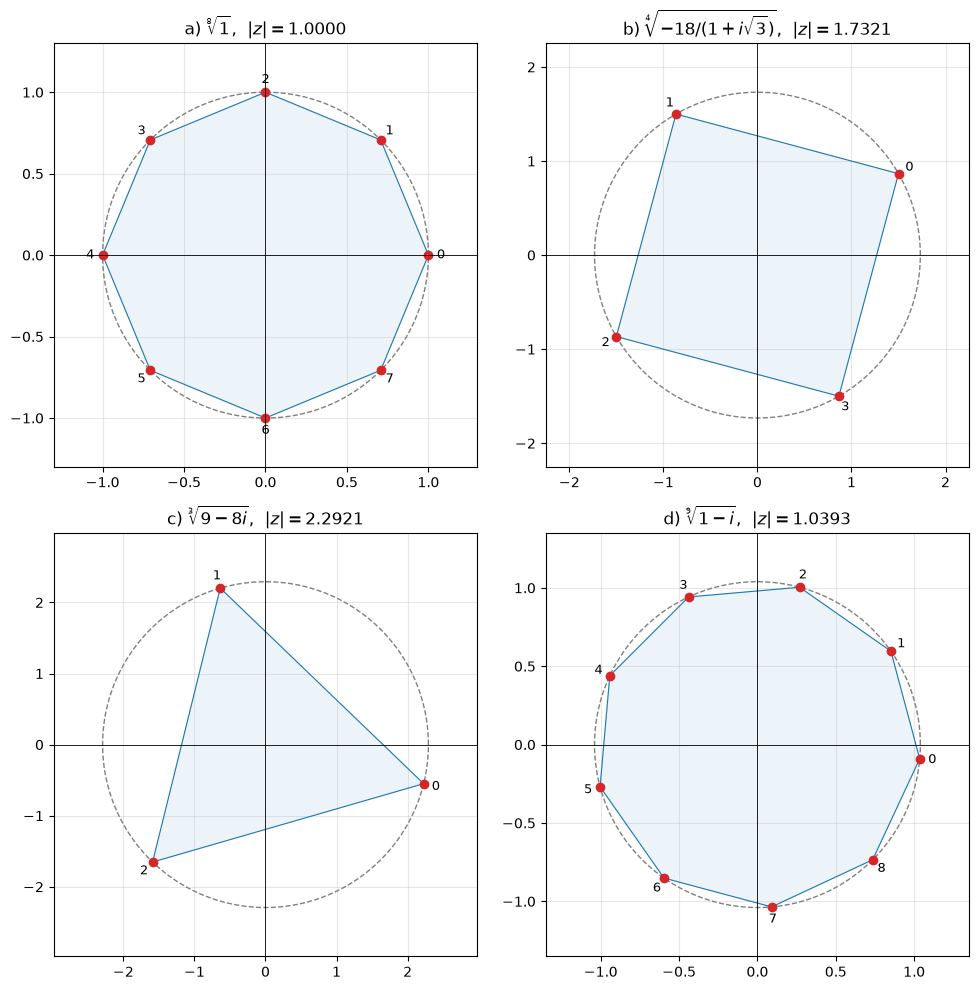

In [3]:
import matplotlib.pyplot as plt

titles = {'a': r'a) $\sqrt[8]{1}$', 'b': r'b) $\sqrt[4]{-18/(1+i\sqrt{3})}$',
          'c': r'c) $\sqrt[3]{9-8i}$', 'd': r'd) $\sqrt[9]{1-i}$'}
t = np.linspace(0, 2*np.pi, 400)
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, name in zip(axs.flat, 'abcd'):
    z = roots[name]
    R = abs(z[0])
    ax.plot(R*np.cos(t), R*np.sin(t), '--', color='gray', lw=1)
    ax.fill(z.real, z.imag, alpha=0.08, color='tab:blue')
    ax.plot(np.append(z.real, z.real[0]), np.append(z.imag, z.imag[0]), '-', color='tab:blue', lw=0.8)
    ax.plot(z.real, z.imag, 'o', color='tab:red')
    for kk, zz in enumerate(z):
        ax.annotate(str(kk), (zz.real, zz.imag), xytext=(zz.real/R*9, zz.imag/R*9),
                    textcoords='offset points', ha='center', va='center', fontsize=9)
    lim = 1.3*R
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_title(titles[name] + f',  $|z|={R:.4f}$')
plt.tight_layout()
plt.show()

### Ответ:

В каждом пункте получается правильный $n$-угольник с центром в нуле (номер вершины $k$ подписан на рисунке).

- **a)** $z_k=e^{i\pi k/4}$, $k=0,\dots,7$: числа $\pm1,\ \pm i,\ \dfrac{\pm1\pm i}{\sqrt2}$.
- **b)** $z_k=\sqrt3\,e^{i(\pi/6+\pi k/2)}$, $k=0,\dots,3$: $\ \dfrac{3}{2}+\dfrac{\sqrt3}{2}i,\ -\dfrac{\sqrt3}{2}+\dfrac32 i,\ -\dfrac32-\dfrac{\sqrt3}2 i,\ \dfrac{\sqrt3}2-\dfrac32 i$.
- **c)** $z_k=145^{1/6}\,e^{i(\arg(9-8i)+2\pi k)/3}$, $k=0,1,2$, где $\arg(9-8i)=-\operatorname{arctg}\frac89\approx-0{,}7266$. Численно: $z_0\approx2{,}2252-0{,}5498i$, $z_1\approx-0{,}6365+2{,}2019i$, $z_2\approx-1{,}5887-1{,}6522i$.
- **d)** $z_k=2^{1/18}\,e^{i(-\pi/4+2\pi k)/9}$, $k=0,\dots,8$.